# **Machine Learning**

**Install and recall libraries**

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import torch
import torch.nn as nn
import torch.optim as optim
from typing import Optional

In [2]:
# Upload datasets

file_path = "/Users/utente/Desktop/Thesis/Thesis/src/Thesis_Dataset.xlsx"
dataset = pd.read_excel(file_path)

rf_path = "/Users/utente/Desktop/Thesis/Thesis/src/Rf.xlsx"
rf = pd.read_excel(rf_path)

In [3]:
# Filter the dataset for all rows where the Date is greater than or equal to July 1969

dataset = dataset[dataset['Date'] >= '1969-07']
rf = rf[rf['Date'] >= '1969-07']
rf = rf.drop(rf.index[-1]) #exclude last observation to align the datasets
rf = rf.iloc[:, [0, -1]] #keep risk-free rate column as it is the information we are interested in
print(dataset.shape)
print(rf.shape)

(663, 50)
(663, 2)


**Merge datasets to obtain returns in excess of the risk-free rate**

In [4]:
# Merge on the 'Date' column
df = pd.merge(dataset, rf, on='Date', how='inner')

# Identify all industry columns (49 columns).
industry_cols = [col for col in df.columns if col not in ['Date', 'RF']]

# Subtract the risk-free rate from each industry column
for col in industry_cols:
    df[col] = df[col] - df['RF']

# Drop RF column
df.drop(columns='RF', inplace=True) 

**Demeaning of returns**

In [5]:
# Separate the 'Date' column
dates = df['Date']
returns_data = df.loc[:, df.columns != 'Date']

# Compute the mean of each portfolio
portfolio_means = returns_data.mean(axis=0)

# Demean the returns
demeaned_returns = returns_data.subtract(portfolio_means, axis=1)

# Verify the unconditional mean is zero
demeaned_means = demeaned_returns.mean(axis=0)
# Check that the absolute values are close to zero
print((demeaned_means.abs() < 1e-12).all())  # Should return True

# Save back the returns dataset as "VWExcessRet"
VWExcessRet = demeaned_returns

VWExcessRet.columns = range(VWExcessRet.shape[1])

True


In [ ]:
# Save dimensions of dataset
num_samples, N = VWExcessRet.shape

## **Autoencoders**

### **OPTUNA hyperparameter optimization**

**Activation function Leaky ReLU is chosen, alongside regularization.**

**First, we run an OPTUNA hyperparameter optimization with latent dimension (size of the bottleneck) fixed at 2. When it comes to hyperparameter tuning, the algorithm searches over the number of layers and the layer sizes (for both encoder and decoder), the Leaky ReLU slope (alpha) and the L2 regularization strength (l2_reg_value).**

In [133]:
def create_model(alpha, l2_reg_value, layer_sizes, N):
    """
    Create an autoencoder model with:
      - Hardcoded latent_dim = 2
      - `layer_sizes` (list[int]) for the hidden layers in the encoder
      - Symmetric decoder (reversed `layer_sizes`)
    """
    l2_reg = keras.regularizers.l2(l2_reg_value)

    # -- Encoder --
    encoder_inputs = keras.Input(shape=(N,))
    x = encoder_inputs
    for size in layer_sizes:
        x = layers.Dense(size, kernel_regularizer=l2_reg)(x)
        x = layers.LeakyReLU(alpha=alpha)(x)

    # Hardcode the latent dimension to 2
    latent = layers.Dense(2, kernel_regularizer=l2_reg, name='latent_layer')(x)

    encoder = keras.Model(encoder_inputs, latent, name="encoder")

    # -- Decoder --
    decoder_inputs = keras.Input(shape=(2,))
    x = decoder_inputs
    # We just reverse the layer_sizes to keep the architecture symmetric
    for size in reversed(layer_sizes):
        x = layers.Dense(size, kernel_regularizer=l2_reg)(x)
        x = layers.LeakyReLU(alpha=alpha)(x)

    # Final reconstruction layer
    decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)
    decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

    # -- Autoencoder --
    autoencoder_inputs = keras.Input(shape=(N,))
    encoded = encoder(autoencoder_inputs)
    decoded = decoder(encoded)
    autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

    return autoencoder, encoder, decoder


def objective(trial):
    """
    Objective function for Optuna to minimize.
    We tune:
      - alpha (LeakyReLU slope)
      - l2_reg_value (L2 regularization strength)
      - n_layers (number of hidden layers in encoder)
      - units_layer_i (layer sizes)
      - learning_rate
      - batch_size
    """
    # 1) Suggest hyperparameters
    alpha = trial.suggest_float("alpha", 1e-4, 1e-1, log=True)
    l2_reg_value = trial.suggest_float("l2_reg_value", 1e-7, 1e-3, log=True)

    # We'll allow up to 4 layers in the encoder/decoder
    n_layers = trial.suggest_int("n_layers", 1, 4)

    # For each layer, pick a size from 16 to 256 in increments of 16
    layer_sizes = []
    for i in range(n_layers):
        size = trial.suggest_int(f"units_layer_{i}", 16, 256, step=16)
        layer_sizes.append(size)

    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])

    # 2) Build the model
    autoencoder, encoder, decoder = create_model(
        alpha=alpha,
        l2_reg_value=l2_reg_value,
        layer_sizes=layer_sizes,
        N=N
    )

    # 3) Compile
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    autoencoder.compile(optimizer=optimizer, loss='mse')

    # 4) Train (shorter epochs for HPO)
    history = autoencoder.fit(
        VWExcessRet,
        VWExcessRet,
        validation_split=0.1,
        epochs=20,
        batch_size=batch_size,
        shuffle=True,
        verbose=0
    )

    # 5) Return the final validation loss (Optuna minimizes this)
    val_loss = history.history["val_loss"][-1]
    return val_loss

In [134]:
# -- Create and run the study --
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)  # increased to 50

print("Best trial:")
best_trial = study.best_trial
print(f"  Value (val_loss): {best_trial.value}")
print("  Params: ")
for key, value in best_trial.params.items():
    print(f"    {key}: {value}")

[I 2025-01-19 23:39:06,994] A new study created in memory with name: no-name-a028a375-c4f7-420c-b7fd-11972ca8f5a5
/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
[I 2025-01-19 23:39:12,489] Trial 0 finished with value: 57.789241790771484 and parameters: {'alpha': 0.0003985011502681635, 'l2_reg_value': 0.0004956413715404572, 'n_layers': 2, 'units_layer_0': 32, 'units_layer_1': 144, 'learning_rate': 1.1359456537067108e-05, 'batch_size': 16}. Best is trial 0 with value: 57.789241790771484.
/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
[I 2025-01-19 23:39:16,153] Trial 1 finished with value: 25.056909561157227 and parameters: {'alpha': 0.0004887534155348308, 'l2_reg_value': 0.0003161162443888821

Best trial:
  Value (val_loss): 23.52104377746582
  Params: 
    alpha: 0.00010616789140513946
    l2_reg_value: 2.3002724318423208e-06
    n_layers: 4
    units_layer_0: 160
    units_layer_1: 192
    units_layer_2: 80
    units_layer_3: 144
    learning_rate: 0.0006032725435054088
    batch_size: 64


In [135]:
# -- Rebuild final model with the best hyperparameters and train--
best_params = study.best_params
best_alpha = best_params["alpha"]
best_l2_reg = best_params["l2_reg_value"]
best_n_layers = best_params["n_layers"]

# Reconstruct the layer_sizes
best_layer_sizes = [
    best_params[f"units_layer_{i}"] for i in range(best_n_layers)
]

best_lr = best_params["learning_rate"]
best_batch_size = best_params["batch_size"]

final_autoencoder, final_encoder, final_decoder = create_model(
    alpha=best_alpha,
    l2_reg_value=best_l2_reg,
    layer_sizes=best_layer_sizes,
    N=N
)

final_optimizer = keras.optimizers.Adam(learning_rate=best_lr)
final_autoencoder.compile(optimizer=final_optimizer, loss='mse')

history_final = final_autoencoder.fit(
    VWExcessRet,
    VWExcessRet,
    epochs=200,   # tried: 100, 200 - settle for this - convergence achieved
    batch_size=best_batch_size,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

# Evaluate reconstruction MSE
reconstructions = final_autoencoder.predict(VWExcessRet)
mse = np.mean((VWExcessRet - reconstructions) ** 2)
print("Final reconstruction MSE with best hyperparams:", mse)

Epoch 1/200


/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 43.7974 - val_loss: 56.4472
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 40.3831 - val_loss: 41.1501
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 27.7138 - val_loss: 30.0260
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 22.2027 - val_loss: 27.3017
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 19.9500 - val_loss: 26.8420
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 20.4191 - val_loss: 26.6661
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 19.9956 - val_loss: 26.7370
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 20.0686 - val_loss: 26.4594
Epoch 9/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 20.3606 - val_loss: 26.4992
Epoch 10/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 20.5249 - val_loss: 26.4901
Epoch 11/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 19.6490 - val_loss: 26.3453
Epoch 12/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 

In [136]:
# Retrieve latent factors from the final encoder
factors_2D = final_encoder.predict(VWExcessRet)
print("Latent factor shape:", factors_2D.shape)
#print("First 5 latent factors:\n", factors_2D[:5])

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Latent factor shape: (663, 2)


**Next, the strong assumption on the size of the bottleneck is relieved.**

In [39]:
def create_model(alpha, l2_reg_value, layer_sizes, latent_dim, N):
    """
    Create an autoencoder model with:
      - `layer_sizes` (list[int]) for the hidden layers in the encoder
      - Latent dimension = `latent_dim` (not hardcoded anymore)
      - Symmetric decoder (reversed `layer_sizes`)
    """
    l2_reg = keras.regularizers.l2(l2_reg_value)

    # -- Encoder --
    encoder_inputs = keras.Input(shape=(N,))
    x = encoder_inputs
    for size in layer_sizes:
        x = layers.Dense(size, kernel_regularizer=l2_reg)(x)
        x = layers.LeakyReLU(alpha=alpha)(x)

    # Latent dimension is a hyperparameter
    latent = layers.Dense(latent_dim, kernel_regularizer=l2_reg, name='latent_layer')(x)
    encoder = keras.Model(encoder_inputs, latent, name="encoder")

    # -- Decoder --
    decoder_inputs = keras.Input(shape=(latent_dim,))
    x = decoder_inputs
    # We just reverse the layer_sizes to keep the architecture symmetric
    for size in reversed(layer_sizes):
        x = layers.Dense(size, kernel_regularizer=l2_reg)(x)
        x = layers.LeakyReLU(alpha=alpha)(x)

    # Final reconstruction layer
    decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)
    decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

    # -- Autoencoder --
    autoencoder_inputs = keras.Input(shape=(N,))
    encoded = encoder(autoencoder_inputs)
    decoded = decoder(encoded)
    autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

    return autoencoder, encoder, decoder

# ---------------------------------------------------
# Objective function for Optuna
# ---------------------------------------------------
def objective(trial):
    """
    Objective function for Optuna to minimize.
    We tune:
      - alpha (LeakyReLU slope)
      - l2_reg_value (L2 regularization strength)
      - n_layers (number of hidden layers)
      - units_layer_i (layer sizes)
      - latent_dim
      - learning_rate
      - batch_size
    """
    # 1) Suggest hyperparameters
    alpha = trial.suggest_float("alpha", 1e-4, 1e-1, log=True)
    l2_reg_value = trial.suggest_float("l2_reg_value", 1e-7, 1e-3, log=True)

    n_layers = trial.suggest_int("n_layers", 1, 4)
    layer_sizes = []
    for i in range(n_layers):
        size = trial.suggest_int(f"units_layer_{i}", 16, 256, step=16)
        layer_sizes.append(size)

    # Now we also tune the bottleneck size 
    latent_dim = trial.suggest_int("latent_dim", 2, 4, step=2) 
    # - This lets Optuna pick any even integer from 2 to 16  for the bottleneck size - range can be adjusted (also step_size)
    # - Let's limit factors to 6 (3 per regime can still be considered reasonable) - also 4
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])

    # 2) Build the model
    autoencoder, encoder, decoder = create_model(
        alpha=alpha,
        l2_reg_value=l2_reg_value,
        layer_sizes=layer_sizes,
        latent_dim=latent_dim,
        N=N
    )

    # 3) Compile
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    autoencoder.compile(optimizer=optimizer, loss='mse')

    # 4) Train (shorter epochs for HPO)
    history = autoencoder.fit(
        VWExcessRet,
        VWExcessRet,
        validation_split=0.1,
        epochs=20,
        batch_size=batch_size,
        shuffle=True,
        verbose=0
    )

    # 5) Return the final validation loss (Optuna minimizes this)
    val_loss = history.history["val_loss"][-1]
    return val_loss

In [40]:
# -- Create and run the study --
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

print("Best trial:")
best_trial = study.best_trial
print(f"  Value (val_loss): {best_trial.value}")
print("  Params: ")
for key, value in best_trial.params.items():
    print(f"    {key}: {value}")

[I 2025-01-18 19:12:34,817] A new study created in memory with name: no-name-cb9282e8-e07a-4513-992c-02973f8dfabb


/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
[I 2025-01-18 19:12:38,302] Trial 0 finished with value: 34.453216552734375 and parameters: {'alpha': 0.0025350235012226463, 'l2_reg_value': 0.0006858708971904772, 'n_layers': 2, 'units_layer_0': 160, 'units_layer_1': 208, 'latent_dim': 4, 'learning_rate': 1.4851248992344857e-05, 'batch_size': 16}. Best is trial 0 with value: 34.453216552734375.
/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
[I 2025-01-18 19:12:41,333] Trial 1 finished with value: 26.304357528686523 and parameters: {'alpha': 0.00029403569449816953, 'l2_reg_value': 1.7355813970680704e-07, 'n_layers': 4, 'units_layer_0': 160, 'units_layer_1': 32, 'units_layer_2': 192, 'units_layer

Best trial:
  Value (val_loss): 20.153764724731445
  Params: 
    alpha: 0.07413937467640445
    l2_reg_value: 1.362350451944554e-06
    n_layers: 3
    units_layer_0: 112
    units_layer_1: 64
    units_layer_2: 80
    latent_dim: 4
    learning_rate: 0.0011010650753874368
    batch_size: 64


In [41]:
# Rebuild & Train Final Model with Best Params
best_params = study.best_params
best_alpha = best_params["alpha"]
best_l2_reg = best_params["l2_reg_value"]
best_n_layers = best_params["n_layers"]

# Reconstruct the layer_sizes
best_layer_sizes = [best_params[f"units_layer_{i}"] for i in range(best_n_layers)]

best_latent_dim = best_params["latent_dim"]
best_lr = best_params["learning_rate"]
best_batch_size = best_params["batch_size"]

final_autoencoder, final_encoder, final_decoder = create_model(
    alpha=best_alpha,
    l2_reg_value=best_l2_reg,
    layer_sizes=best_layer_sizes,
    latent_dim=best_latent_dim,
    N=N
)

final_optimizer = keras.optimizers.Adam(learning_rate=best_lr)
final_autoencoder.compile(optimizer=final_optimizer, loss='mse')

history_final = final_autoencoder.fit(
    VWExcessRet,
    VWExcessRet,
    epochs=200,   # to align, sets to 200
    batch_size=best_batch_size,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

# Evaluate & Retrieve Factors
# Compute the MSE reconstruction error
reconstructions = final_autoencoder.predict(VWExcessRet) 
mse = np.mean((VWExcessRet - reconstructions) ** 2)
print("Final reconstruction MSE with best hyperparams:", mse)

Epoch 1/200


/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 41.8195 - val_loss: 47.1474
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 36.6221 - val_loss: 31.9574
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 23.1945 - val_loss: 27.4385
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 20.5573 - val_loss: 26.8366
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 20.4728 - val_loss: 26.7361
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 19.4968 - val_loss: 26.3861
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 19.4521 - val_loss: 25.9848
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 19.2186 - val_loss: 25.4512
Epoch 9/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 19.2993 - val_loss: 24.9739
Epoch 10/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 17.8996 - val_loss: 24.6056
Epoch 11/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 18.1469 - val_loss: 23.9574
Epoch 12/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

In [33]:
# Retrieve latent factors from the final encoder
factors_16D = final_encoder.predict(VWExcessRet)
print("Latent factor shape:", factors_16D.shape)  # (num_samples, best_latent_dim)
#print("First 5 latent factors:\n", factors[:5])

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Latent factor shape: (663, 16)


As the objective of the function itself is to minimize as much as possible the loss of information during the reconstruction of the original dataset, it is only natural that the biggest allowed dimension of factors will be chosen. In fact, a wider bottleneck allows for better reconstruction. The economic significance of 16 factors is questionable.

**Final reconstruction MSE with best hyperparams: 3.327842704560372 (for 16 factors)**

To test effectiveness of various solutions, we'll save all of these objects.

**Below are the reconstructed MSE and factors when we allow the OPTUNA to look for size of bottleneck anywhere from 2 to 6.**

**Final reconstruction MSE with best hyperparams: 8.96835015201493 (for 6 factors)**

In [38]:
# Retrieve latent factors from the final encoder
factors_6D = final_encoder.predict(VWExcessRet)
print("Latent factor shape:", factors_6D.shape)  # (num_samples, best_latent_dim)
#print("First 5 latent factors:\n", factors[:5])

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Latent factor shape: (663, 6)


**Let us also save the results for 4 factors.**

**Final reconstruction MSE with best hyperparams: 9.749699060241422**

In [42]:
# Retrieve latent factors from the final encoder
factors_4D = final_encoder.predict(VWExcessRet)
print("Latent factor shape:", factors_4D.shape)  # (num_samples, best_latent_dim)
#print("First 5 latent factors:\n", factors[:5])

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Latent factor shape: (663, 4)


#### **Exploratory Data Analysis on Factors**

In [137]:
# Explore factors_2D object
print("Mean per dimension:", np.mean(factors_2D, axis=0))
print("Std  per dimension:", np.std(factors_2D,  axis=0))
print("Min  per dimension:", np.min(factors_2D,  axis=0))
print("Max  per dimension:", np.max(factors_2D,  axis=0))


Mean per dimension: [-1.0154768  1.1623185]
Std  per dimension: [35.624374 43.84555 ]
Min  per dimension: [-154.87999 -201.40674]
Max  per dimension: [121.147446 221.24379 ]


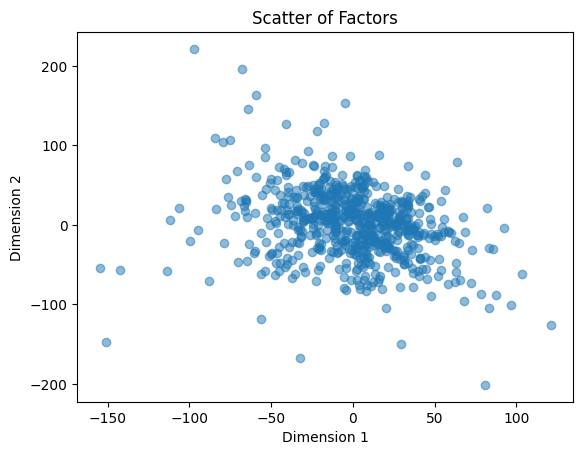

In [138]:
plt.scatter(factors_2D[:, 0], factors_2D[:, 1], alpha=0.5)
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("Scatter of Factors")
plt.show()

In [74]:
data_mean = np.array([-2.6607568, 4.5089893])
data_std  = np.array([31.549097, 21.632383])

# Means for the 2 states:
mean_state1 = data_mean - 0.5 * data_std
mean_state2 = data_mean + 0.5 * data_std
init_means = np.stack([mean_state1, mean_state2], axis=0)  # shape (2, 2)

# Log-variances: let’s do half the global std => var ~ (0.5 * sigma)^2
var_init = (0.5 * data_std)**2
logvar_init = np.log(var_init)
# replicate for both states:
init_logvars = np.stack([logvar_init, logvar_init], axis=0)  # shape (2, 2)

##### **K-Means**

In [99]:
from sklearn.cluster import KMeans
import numpy as np

kmeans = KMeans(n_clusters=2, random_state=42).fit(factors_2D)
cluster_centers = kmeans.cluster_centers_  # shape (2, 2)

# Assign each point to nearest cluster => compute variances:
labels = kmeans.labels_
init_logvars = []
for i in range(2):
    data_in_cluster = factors_2D[labels == i]
    # diagonal variance per dimension
    var_i = data_in_cluster.var(axis=0)  # shape (2,)
    # If cluster is small, you might want to add an epsilon
    logvar_i = np.log(var_i + 1e-3)
    init_logvars.append(logvar_i)
init_logvars = np.stack(init_logvars, axis=0)  # shape (2,2)

## **Neural Hidden Markov Model**

**The classes defined below are for 2D factor data.**

**Further down the line, a generalized code that allows for different dimensions will be implemented.**

In [ ]:
class NeuralHMM(nn.Module):
    """
    A 2-state Neural HMM for 2D factor data.
    """
    def __init__(self,
                 num_states=2,
                 factor_dim=2,
                 w1=0.1,
                 w2=0.05):
        super().__init__()
        assert num_states == 2
        
        # -- Basic checks on w1, w2 --
        if not (0 < w1 < 0.5):
            raise ValueError("w1 must be in (0, 0.5).")
        if not (0 < w2 < 0.5):
            raise ValueError("w2 must be in (0, 0.5).")
        if w1 <= w2:
            raise ValueError("w1 must be strictly greater than w2 to reflect 'state1' being more probable.")
        
        self.num_states = num_states
        self.factor_dim = factor_dim
        
        # --- Transition Matrix Parameters ---
        # We'll specify the initial estimate in probability space:
        P_init = torch.tensor([
            [0.5 + w1, 0.5 - w1],
            [0.5 - w2, 0.5 + w2],
        ], dtype=torch.float32)
        
        # Convert to log space => trans_logits
        # We store it as an nn.Parameter so it is learnable
        self.trans_logits = nn.Parameter(torch.log(P_init))
        
        # --- Emission Parameters ---
        # We'll learn a mean and diagonal log-variance for each state.
        self.state_means = nn.Parameter(torch.zeros(num_states, factor_dim))
        self.state_logvars = nn.Parameter(torch.zeros(num_states, factor_dim))

        #Manual Offset
        #self.state_means = nn.Parameter(torch.tensor(init_means, dtype=torch.float32))
        #self.state_logvars = nn.Parameter(torch.tensor(init_logvars, dtype=torch.float32))

        #K-Means
        #self.state_means = nn.Parameter(torch.tensor(cluster_centers, dtype=torch.float32))
        #self.state_logvars = nn.Parameter(torch.tensor(init_logvars, dtype=torch.float32))

    def forward(self, factors):
        """
        Normally in PyTorch, 'forward' is the neural net computation.
        But in an HMM, we typically define a forward-backward pass for
        the probability model. For clarity, we won't do it here.
        
        Instead, we'll define separate methods:
        - get_trans_matrix()
        - log_emission_prob()
        - forward_backward()
        """
        raise NotImplementedError("Use get_trans_matrix() and forward_backward() explicitly.")
    
    def get_trans_matrix(self):
        """
        Convert self.trans_logits into a proper transition matrix via row-wise softmax.
        Returns: P of shape (2, 2) with each row summing to 1.
        """
        return nn.functional.softmax(self.trans_logits, dim=1)
    
    def log_emission_prob(self, factors):
        """
        Compute log p(factors_t | state), for each state.
        
        factors: shape (T, factor_dim)
        Return log_prob: shape (T, num_states)
        """
        # factors -> shape (T, factor_dim)
        T = factors.shape[0]
        
        # Expand for broadcasting:
        # state_means: (2, factor_dim)
        # We'll compare each of the T points to each state => want shape (T, 2)
        
        # We'll do a simple diagonal Gaussian log probability:
        # log p(x | s=j) = -0.5 * sum( log(2π) + log_var_j + (x - mean_j)^2 / exp(log_var_j) )
        
        # shape (2, factor_dim)
        means = self.state_means  
        logvars = self.state_logvars
        
        # We'll broadcast:
        #   factors.unsqueeze(1).shape => (T, 1, factor_dim)
        #   means.shape => (2, factor_dim) => broadcast to (1, 2, factor_dim)
        
        diff = factors.unsqueeze(1) - means.unsqueeze(0)  # (T,2,factor_dim)
        logvar = logvars.unsqueeze(0)  # (1,2,factor_dim)
        
        # diag Gaussian log-likelihood:
        # sum over factor_dim => shape (T,2)
        log_probs = -0.5 * torch.sum(
            (diff**2) / torch.exp(logvar) + logvar + np.log(2*np.pi),
            dim=2
        )
        # log_probs => (T,2)
        return log_probs
    
    def forward_backward(self, factors):
        T = factors.shape[0]
        log_p_emit = self.log_emission_prob(factors)  # (T,2)
        P = self.get_trans_matrix()                   # (2,2)
    
        # Convert to log space
        log_P = torch.log(P)
    
        # --- Forward pass (alpha) ---
        alpha = torch.zeros(T, self.num_states, device=factors.device)  # log alpha[t,j]
    
        # For simplicity, uniform initial distribution:
        pi = torch.tensor([0.5, 0.5], dtype=torch.float32, device=factors.device)
        #pi = torch.tensor([0.872, 0.128], dtype=torch.float32, device=factors.device)
        #This is a direct way to incorporate that “on any random month, the chance we’re in a recession is about 12.8%” at the start of the sequence. 
        #After the first time step, the forward-backward recursions handle the rest.
        alpha[0] = torch.log(pi) + log_p_emit[0]  # shape (2,)
    
        for t in range(1, T):
             # shape of prev_alpha => (2,2); logsumexp over dim=0 => (2,)
             prev_alpha = alpha[t-1].unsqueeze(1) + log_P
             alpha[t] = log_p_emit[t] + torch.logsumexp(prev_alpha, dim=0)
    
        # total log-likelihood = log p(x_{1:T})
        ll = torch.logsumexp(alpha[T-1], dim=0)
    
        # --- Backward pass (beta) ---
        beta = torch.zeros(T, self.num_states, device=factors.device)  # log beta[t,j]
        # beta[T-1,:] = 0 in log space => shape (2, )
    
        for t in reversed(range(T-1)):
             # next_beta shape => (2,2)
             next_beta = log_P + log_p_emit[t+1] + beta[t+1]
             # sum over next state dimension => shape (2,)
             beta[t] = torch.logsumexp(next_beta, dim=1)
    
         # --- Smoothed probabilities gamma[t,j] ---
         # log p(s_t=j | all obs) = alpha[t,j] + beta[t,j] - ll
        gamma_log = alpha + beta - ll
        gamma = torch.exp(gamma_log)  # shape (T,2)
    
        # Normalize row-wise to ensure sum(gamma[t,:]) = 1
        gamma_sum = gamma.sum(dim=1, keepdim=True)  # shape (T,1)
        gamma = gamma / gamma_sum
    
        return ll, gamma
    
    def negative_log_likelihood(self, factors):
        """ Compute negative log-likelihood for the entire sequence. """
        ll, _ = self.forward_backward(factors)
        return -ll
    
    def predict_states(self, factors):
        """
        Compute the smoothed posterior probabilities gamma,
        then choose the argmax state at each time.
        
        Returns:
          states (T,) - the most likely discrete state at each time
          gamma   (T,2) - the distribution over states
        """
        _, gamma = self.forward_backward(factors)
        # gamma is shape (T,2)
        states = torch.argmax(gamma, dim=1)
        return states, gamma

In [ ]:
def train_neural_hmm(factors, num_epochs=50, lr=1e-2):
    # Convert to Torch tensor
    factors_tensor = torch.tensor(factors, dtype=torch.float32)
    
    model = NeuralHMM(num_states=2, factor_dim=2, w1=0.49, w2=0.1) 
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        
        nll = model.negative_log_likelihood(factors_tensor)
        nll.backward()
        
        optimizer.step()
        
        with torch.no_grad():
            ll = -nll.item()
        print(f"Epoch {epoch+1}/{num_epochs}, Log-Likelihood = {ll:.4f}")
    
    return model

In [123]:
trained_model = train_neural_hmm(factors_2D, num_epochs=2000, lr=1e-2)

# After training
states, gamma = trained_model.predict_states(torch.tensor(factors_2D, dtype=torch.float32))
print("States shape:", states.shape)    # (T,)
print("Gamma shape:", gamma.shape)      # (T,2)

# Transition matrix
with torch.no_grad():
    P_est = trained_model.get_trans_matrix()
print("Estimated Transition Matrix:\n", P_est)

Epoch 1/2000, Log-Likelihood = -6565.1157
Epoch 2/2000, Log-Likelihood = -6557.5166
Epoch 3/2000, Log-Likelihood = -6550.0435
Epoch 4/2000, Log-Likelihood = -6542.7930
Epoch 5/2000, Log-Likelihood = -6535.6011
Epoch 6/2000, Log-Likelihood = -6528.6274
Epoch 7/2000, Log-Likelihood = -6521.7334
Epoch 8/2000, Log-Likelihood = -6515.0669
Epoch 9/2000, Log-Likelihood = -6508.4565
Epoch 10/2000, Log-Likelihood = -6502.0669
Epoch 11/2000, Log-Likelihood = -6495.7705
Epoch 12/2000, Log-Likelihood = -6489.6846
Epoch 13/2000, Log-Likelihood = -6483.6665
Epoch 14/2000, Log-Likelihood = -6477.8472
Epoch 15/2000, Log-Likelihood = -6472.1343
Epoch 16/2000, Log-Likelihood = -6466.6104
Epoch 17/2000, Log-Likelihood = -6461.1582
Epoch 18/2000, Log-Likelihood = -6455.9707
Epoch 19/2000, Log-Likelihood = -6450.7866
Epoch 20/2000, Log-Likelihood = -6445.8574
Epoch 21/2000, Log-Likelihood = -6440.9614
Epoch 22/2000, Log-Likelihood = -6436.2695
Epoch 23/2000, Log-Likelihood = -6431.7124
Epoch 24/2000, Log-L

In [124]:
#save unconditional probabilities and most probable state as pd dataframe for further exploration
gammadf = pd.DataFrame(gamma.detach().numpy())
statesdf = pd.DataFrame(states.detach().numpy())

In [125]:
# Count the occurrences of 0 and 1
count_zeros = (states == 0).sum().item()
count_ones = (states == 1).sum().item()

# Print the results
print(f"Number of 0s: {count_zeros}")
print(f"Number of 1s: {count_ones}")

Number of 0s: 165
Number of 1s: 498


### **NHMM - OPTUNA Optimization**

In [142]:
# -----------------------
# 1. Define the HMM class
# -----------------------
class NeuralHMM(nn.Module):
    """
    A 2-state Neural HMM for 2D factor data.
    """
    def __init__(self,
                 num_states=2,
                 factor_dim=2,
                 w1=0.1,
                 w2=0.05):
        super().__init__()
        assert num_states == 2
        
        # -- Basic checks on w1, w2 --
        if not (0 < w1 < 0.5):
            raise ValueError("w1 must be in (0, 0.5).")
        if not (0 < w2 < 0.5):
            raise ValueError("w2 must be in (0, 0.5).")
        if w1 <= w2:
            raise ValueError("w1 must be strictly greater than w2.")
        
        self.num_states = num_states
        self.factor_dim = factor_dim
        
        # --- Transition Matrix Parameters ---
        P_init = torch.tensor([
            [0.5 + w1, 0.5 - w1],
            [0.5 - w2, 0.5 + w2],
        ], dtype=torch.float32)
        
        self.trans_logits = nn.Parameter(torch.log(P_init))
        
        # --- Emission Parameters ---
        self.state_means = nn.Parameter(torch.zeros(num_states, factor_dim))
        self.state_logvars = nn.Parameter(torch.zeros(num_states, factor_dim))

    def forward(self, factors):
        """
        In an HMM, we typically define forward-backward separately.
        Here, forward is unused.
        """
        raise NotImplementedError(
            "Use get_trans_matrix() and forward_backward() explicitly."
        )
    
    def get_trans_matrix(self):
        return nn.functional.softmax(self.trans_logits, dim=1)
    
    def log_emission_prob(self, factors):
        T = factors.shape[0]
        
        means = self.state_means
        logvars = self.state_logvars
        
        diff = factors.unsqueeze(1) - means.unsqueeze(0)  # (T,2,factor_dim)
        logvar = logvars.unsqueeze(0)                     # (1,2,factor_dim)
        
        # diagonal Gaussian log-likelihood
        log_probs = -0.5 * torch.sum(
            (diff ** 2) / torch.exp(logvar) + logvar + np.log(2 * np.pi),
            dim=2
        )
        return log_probs
    
    def forward_backward(self, factors):
        T = factors.shape[0]
        log_p_emit = self.log_emission_prob(factors)  # (T,2)
        P = self.get_trans_matrix()                   # (2,2)
        log_P = torch.log(P)
    
        # -- Forward pass (alpha) --
        alpha = torch.zeros(T, self.num_states, device=factors.device)
        pi = torch.tensor([0.5, 0.5], dtype=torch.float32, device=factors.device)
        alpha[0] = torch.log(pi) + log_p_emit[0]
    
        for t in range(1, T):
            prev_alpha = alpha[t - 1].unsqueeze(1) + log_P
            alpha[t] = log_p_emit[t] + torch.logsumexp(prev_alpha, dim=0)
    
        ll = torch.logsumexp(alpha[T - 1], dim=0)
    
        # -- Backward pass (beta) --
        beta = torch.zeros(T, self.num_states, device=factors.device)
        for t in reversed(range(T - 1)):
            next_beta = log_P + log_p_emit[t + 1] + beta[t + 1]
            beta[t] = torch.logsumexp(next_beta, dim=1)
    
        # -- Smoothed posterior (gamma) --
        gamma_log = alpha + beta - ll
        gamma = torch.exp(gamma_log)
        gamma = gamma / gamma.sum(dim=1, keepdim=True)
    
        return ll, gamma
    
    def negative_log_likelihood(self, factors):
        ll, _ = self.forward_backward(factors)
        return -ll
    
    def predict_states(self, factors):
        _, gamma = self.forward_backward(factors)
        states = torch.argmax(gamma, dim=1)
        return states, gamma

In [143]:
# ------------------------------
# 2. Define a train helper func
# ------------------------------
def train_neural_hmm(factors, model, num_epochs=50, lr=1e-2, trial=None):
    """
    Train the NeuralHMM and optionally report to Optuna for pruning.
    """
    optimizer = optim.Adam(model.parameters(), lr=lr)
    factors_tensor = torch.tensor(factors, dtype=torch.float32)

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        
        nll = model.negative_log_likelihood(factors_tensor)
        nll.backward()
        
        optimizer.step()
        
        # If we want to do pruning with Optuna,
        # we can report the intermediate value each epoch.
        if trial is not None:
            trial.report(nll.item(), epoch)
            
            # If the trial should be pruned (e.g., if the current NLL is not promising),
            # this call will raise an exception to stop early.
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()
    
    # Final NLL after all epochs
    final_nll = model.negative_log_likelihood(factors_tensor).item()
    return final_nll

In [144]:
# ------------------------------
# 3. Define the Optuna objective
# ------------------------------
def objective(trial, factors_2D):
    """
    Objective function for Optuna.
    1) Suggest hyperparams: w1, w2, learning rate, #epochs, etc.
    2) Build and train model.
    3) Return the final negative log-likelihood (the objective).
    """

    # Sample w1, w2 such that 0 < w2 < w1 < 0.5
    # We'll sample in ranges that make sense, then prune if w1 <= w2.
    w1 = trial.suggest_float("w1", 0.01, 0.49)
    w2 = trial.suggest_float("w2", 0.01, 0.49)
    if w1 <= w2:
        raise optuna.exceptions.TrialPruned("w1 <= w2, pruning this trial.")
    
    # Sample learning rate (loguniform means sampling from e.g. [1e-4, 1e-1])
    lr = trial.suggest_loguniform("lr", 1e-4, 1e-1)
    
    # You could also sample the number of epochs if you want:
    num_epochs = trial.suggest_categorical("num_epochs", [200, 500, 1000])
    
    # Build the model with the sampled hyperparams
    model = NeuralHMM(num_states=2, factor_dim=2, w1=w1, w2=w2)
    
    # Train the model
    final_nll = train_neural_hmm(
        factors=factors_2D,
        model=model,
        num_epochs=num_epochs,
        lr=lr,
        trial=trial
    )
    
    # Return the objective (Optuna will try to minimize this)
    return final_nll

In [145]:
# -------------------------------------------------
# 4. Running the study on your dataset (factors_2D)
# -------------------------------------------------
def run_optuna_optimization(factors_2D, n_trials=20):
    # Create a study that aims to minimize the objective function
    study = optuna.create_study(direction="minimize")
    
    # Optimize over n_trials
    study.optimize(lambda t: objective(t, factors_2D),
                   n_trials=n_trials,
                   timeout=None,  # or set a time limit (seconds)
                   catch=(ValueError,))  # In case your model raises ValueErrors
    
    print("Number of finished trials: ", len(study.trials))
    print("Best trial:")
    trial = study.best_trial
    
    print("  Value: ", trial.value)
    print("  Params: ")
    for key, value in trial.params.items():
        print(f"    {key}: {value}")
    
    return study

In [ ]:
# -------------------------
# 5. Example usage
# -------------------------
if __name__ == "__main__":
    
    factors_2D = factors_2D
    study_result = run_optuna_optimization(factors_2D, n_trials=50)
    
    # After the study completes, retrieve the best hyperparams:
    best_params = study_result.best_trial.params
    print("Best Hyperparameters:", best_params)
    
    # You can retrain a final model with these params if desired:
    best_model = NeuralHMM(
        num_states=2,
        factor_dim=2,
        w1=best_params["w1"],
        w2=best_params["w2"],
    )
    # Train with best LR and #epochs:
    train_neural_hmm(
        factors=factors_2D,
        model=best_model,
        num_epochs=best_params["num_epochs"],
        lr=best_params["lr"]
    )
    
    # Inspect final results:
    with torch.no_grad():
        states, gamma = best_model.predict_states(torch.tensor(factors_2D, dtype=torch.float32))
        P_est = best_model.get_trans_matrix()
    
    print("Estimated Transition Matrix:\n", P_est)

[I 2025-01-19 23:58:52,664] A new study created in memory with name: no-name-9b146d91-f602-4723-a711-5ec5aec68a5d
/var/folders/20/jt1tkq213g3frrgs2z5n6zgc0000gn/T/ipykernel_89146/1796116444.py:20: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  lr = trial.suggest_loguniform("lr", 1e-4, 1e-1)
[I 2025-01-19 23:59:28,130] Trial 0 finished with value: 228910.375 and parameters: {'w1': 0.4810960356992837, 'w2': 0.42450245362826305, 'lr': 0.009402084250401977, 'num_epochs': 500}. Best is trial 0 with value: 228910.375.
[I 2025-01-19 23:59:41,607] Trial 1 finished with value: 959593.625 and parameters: {'w1': 0.41626973940470474, 'w2': 0.09396055101007977, 'lr': 0.0019201026972061835, 'num_epochs': 200}. Best is trial 0 with value: 228910.375.
[I 2025-01-19 23:59:56,327] Trial 2 finished with value: 439801.375 and parameters: {'w1': 0.4

Number of finished trials:  50
Best trial:
  Value:  7160.01708984375
  Params: 
    w1: 0.28392302695003685
    w2: 0.21221445677884115
    lr: 0.08432677174814517
    num_epochs: 1000
Best Hyperparameters: {'w1': 0.28392302695003685, 'w2': 0.21221445677884115, 'lr': 0.08432677174814517, 'num_epochs': 1000}
Final State Predictions: tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1,

In [147]:
# Suppose your study result is stored in 'study_result'
# e.g., from: study_result = run_optuna_optimization(factors_2D, n_trials=20)

# 1) Retrieve best hyperparameters
best_trial = study_result.best_trial
best_params = best_trial.params
print("Best hyperparams:", best_params)

# 2) Create a final NeuralHMM model with these params
final_model = NeuralHMM(
    num_states=2,
    factor_dim=2,
    w1=best_params["w1"],
    w2=best_params["w2"]
)

# 3) Retrain the final model for 1000 epochs
final_nll = train_neural_hmm(
    factors=factors_2D,
    model=final_model,
    num_epochs=best_params['num_epochs'],        # Force 1000 epochs
    lr=best_params["lr"],   # Use the best LR from Optuna
    trial=None              # No pruning here
)

# Print final negative log-likelihood
print(f"Final model NLL after 1000 epochs: {final_nll:.4f}")

# 4) (Optional) Inspect or evaluate the final model
with torch.no_grad():
    states, gamma = final_model.predict_states(torch.tensor(factors_2D, dtype=torch.float32))
    P_est = final_model.get_trans_matrix()

print("Final State Predictions:", states)
print("Estimated Transition Matrix:\n", P_est)


Best hyperparams: {'w1': 0.28392302695003685, 'w2': 0.21221445677884115, 'lr': 0.08432677174814517, 'num_epochs': 1000}
Final model NLL after 1000 epochs: 7160.0171
Final State Predictions: tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1,